# Refined Fluent `.out` Post-Processing

This notebook post-processes Fluent report `.out` files only. It is designed for:

- **continuation runs** split across several folders; later folders overwrite earlier data at overlapping flow times,
- **up to three result configurations** for comparison,
- **fuzzy/robust detection** of report names and variable names such as `temp`/`temperature`, `max-cfl`/`cfl`, `refvol`/`reference`,
- report files containing **one or multiple variables**,
- graceful handling of missing files or variables (`[not found] ...` is printed instead of stopping),
- mass-flow plots with **kg/s on the left** and **equivalent L/min on the right**,
- pressure, temperature, CFL, \(y^+\), time-step, iteration, and correlation plots.

### Important unit assumptions

The notebook assumes the Fluent reports contain:

- flow time in **s**,
- temperature in **K**,
- pressure in **Pa**,
- mass flow in **kg/s**,
- \(\Delta t\) in **s**.

For pressure, the plots are explicitly labeled **gauge pressure**. This is correct **if the Fluent report quantity is Static Pressure**: Fluent Static Pressure is relative to the configured Operating Pressure. The default configuration below uses an operating pressure of **1 bar = 101325 Pa**. If your case uses 101325 Pa or another value, change `OPERATING_PRESSURE_PA`.

The L/min scale uses a configurable reference density. It is therefore an **equivalent/reference volume flow**, not necessarily the instantaneous local volumetric flow of a compressible solution.


## 0. Define the result configurations

In [17]:
from pathlib import Path

# ============================================================
# USER INPUT
# ============================================================
# Up to 3 result configurations.
#
# For ONE result, several paths are interpreted as continuation
# segments of the same simulation:
#   paths[0] -> e.g. 0-1 s
#   paths[1] -> e.g. 1-5 s
#
# If flow times overlap, the LATER path in the list wins.
#
# Leave "paths": [] for unused result slots.

RESULTS = [
    {
        "name": "One Inlet",
        "paths": [
            r"BatteryCells_Valve_Open\BatteryCell-OneInlet\results\v5_big\local",
            r"BatteryCells_Valve_Open\BatteryCell-OneInlet\results\v5_big\cluster",
        ],
    },
    {
        "name": "One Inlet",
        "paths": [
            # r"D:\CFD\One_Inlet",
        ],
    },
    {
        "name": "Third Result",
        "paths": [
            # r"D:\CFD\Third_Result",
        ],
    },
]

# ============================================================
# PHYSICAL / PLOTTING SETTINGS
# ============================================================

# Dry-air reference density at 20 °C and 1.000 bar absolute,
# using the ideal-gas relation. Change this if you prefer another
# reference convention (e.g. 1 atm -> about 1.204 kg/m^3).
AIR_DENSITY_KG_M3 = 1.188

# Operating pressure used only for explanatory labels.
# 1 bar = 100000 Pa.
OPERATING_PRESSURE_PA = 101325.0

# Keep False to retain Fluent's sign convention for mass flow.
PLOT_ABSOLUTE_MASSFLOW = False

# Duplicate flow times are matched after rounding to this precision.
FLOW_TIME_ROUND_DECIMALS = 10

# Figure sizes.
FIGSIZE = (10, 5.5)
FIGSIZE_WIDE = (14, 5.2)

# Line style identifies the result configuration.
RESULT_LINESTYLES = ["-", "--", ":"]

# Small markers can help correlation plots; set to None to disable.
CORRELATION_MARKER = None


def _clean_paths(paths):
    cleaned = []
    for p in paths:
        if p is None:
            continue
        p = str(p).strip()
        if not p:
            continue
        cleaned.append(Path(p).expanduser())
    return cleaned


ACTIVE_RESULT_CONFIGS = []

print("Configured results:")
for result_index, cfg in enumerate(RESULTS):
    name = str(cfg.get("name", f"Result {result_index + 1}")).strip()
    paths = _clean_paths(cfg.get("paths", []))

    if not paths:
        print(f"  [{result_index + 1}] {name}: no paths defined -> skipped")
        continue

    print(f"  [{result_index + 1}] {name}")
    for path_index, folder in enumerate(paths, start=1):
        status = "OK" if folder.exists() else "MISSING"
        print(f"      path {path_index}: [{status}] {folder}")

    ACTIVE_RESULT_CONFIGS.append({
        "name": name,
        "paths": paths,
        "result_index": result_index,
        "linestyle": RESULT_LINESTYLES[result_index % len(RESULT_LINESTYLES)],
    })

if not ACTIVE_RESULT_CONFIGS:
    print(
        "\n[warning] No result paths are currently defined. "
        "Edit RESULTS above, then run the notebook again."
    )


Configured results:
  [1] One Inlet
      path 1: [OK] BatteryCells_Valve_Open\BatteryCell-OneInlet\results\v5_big\local
      path 2: [OK] BatteryCells_Valve_Open\BatteryCell-OneInlet\results\v5_big\cluster
  [2] One Inlet: no paths defined -> skipped
  [3] Third Result: no paths defined -> skipped


## 1. Parser, detection, merging, and plotting helpers

In [18]:
import re
import math
import difflib
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


FLOAT_RE = re.compile(
    r"[-+]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eEdD][-+]?\d+)?"
)


# ------------------------------------------------------------
# Basic text normalization
# ------------------------------------------------------------

def normalize_name(text):
    """Lower-case and remove punctuation so spelling variants compare robustly."""
    return re.sub(r"[^a-z0-9]+", "", str(text).lower())


def normalize_file_stem(filename):
    stem = Path(filename).stem.lower()
    for suffix in ("-rfile", "_rfile", "-report", "_report"):
        stem = stem.replace(suffix, "")
    return normalize_name(stem)


def pretty_name(text):
    text = str(text).strip().strip('"').strip("'")
    text = text.replace("_", " ").replace("-", " ")
    return " ".join(word.capitalize() for word in text.split())


def _quoted_tokens(line):
    return [x.strip() for x in re.findall(r'"([^"]+)"', line)]


def _numeric_tokens(line):
    values = []
    for token in FLOAT_RE.findall(line):
        try:
            value = float(token.replace("D", "E").replace("d", "e"))
            if math.isfinite(value):
                values.append(value)
        except ValueError:
            pass
    return values


# ------------------------------------------------------------
# Fluent .out reader
# ------------------------------------------------------------

def read_fluent_out(path):
    """
    Read one Fluent report .out file and return LONG-format rows:
      flow_time, variable_name, var_norm, value, source_file,
      source_file_norm

    Handles files containing one or several report variables.
    """
    path = Path(path)

    if not path.exists():
        print(f"[not found] {path}")
        return None

    try:
        text = path.read_text(encoding="utf-8", errors="replace")
    except Exception as exc:
        print(f"[not found] could not read {path}: {exc}")
        return None

    lines = text.splitlines()

    # Prefer the quoted header with the largest number of fields and a flow-time field.
    header_candidates = []
    for line in lines:
        tokens = _quoted_tokens(line)
        if tokens and any("flow" in normalize_name(t) and "time" in normalize_name(t) for t in tokens):
            header_candidates.append(tokens)

    header = max(header_candidates, key=len) if header_candidates else None

    numeric_rows = []
    for line in lines:
        stripped = line.strip()
        if not stripped:
            continue

        # Fluent data rows normally start numerically. This prevents numbers
        # embedded in comments/headers from becoming fake data.
        if stripped[0] not in "+-.0123456789":
            continue

        vals = _numeric_tokens(stripped)
        if len(vals) >= 2:
            numeric_rows.append(vals)

    if not numeric_rows:
        print(f"[not found] no numeric report rows in {path.name}")
        return None

    widths = pd.Series([len(row) for row in numeric_rows]).value_counts()
    width = int(widths.index[0])

    rows = [row[:width] for row in numeric_rows if len(row) >= width]
    arr = np.asarray(rows, dtype=float)

    if arr.size == 0:
        print(f"[not found] empty numeric table in {path.name}")
        return None

    # Establish column labels.
    if header is not None and len(header) == width:
        columns = header
    elif header is not None and len(header) == width - 1:
        # Rare Fluent format where numeric output carries an extra leading index.
        columns = ["row-index"] + header
    else:
        columns = [f"column-{i}" for i in range(width)]
        print(
            f"[warning] {path.name}: could not align header with {width} numeric columns. "
            "Using fallback column names."
        )

    col_norms = [normalize_name(c) for c in columns]

    # Detect flow-time column.
    flow_candidates = [
        i for i, n in enumerate(col_norms)
        if n in {"flowtime", "timeflow"} or ("flow" in n and "time" in n)
    ]

    if flow_candidates:
        flow_idx = flow_candidates[0]
    else:
        # Fallback only; most Fluent report files contain an explicit flow-time header.
        flow_idx = 1 if width >= 3 else 0
        print(
            f"[warning] {path.name}: flow-time header not recognized; "
            f"assuming numeric column {flow_idx}."
        )

    meta_exact = {
        "timestep",
        "timestepindex",
        "iteration",
        "iterations",
        "iter",
        "rowindex",
        "flowtime",
        "timeflow",
    }

    frames = []

    for j, (raw_name, norm_name) in enumerate(zip(columns, col_norms)):
        if j == flow_idx:
            continue
        if norm_name in meta_exact:
            continue

        # If fallback labels were necessary and this is a one-variable file,
        # use the file stem as the semantic name.
        semantic_raw = raw_name
        semantic_norm = norm_name

        if raw_name.startswith("column-") and width <= 3:
            semantic_raw = Path(path).stem
            semantic_norm = normalize_file_stem(path.name)

        part = pd.DataFrame({
            "flow_time": arr[:, flow_idx],
            "variable_name": semantic_raw,
            "var_norm": semantic_norm,
            "value": arr[:, j],
            "source_file": path.name,
            "source_file_norm": normalize_file_stem(path.name),
        })

        part = part.replace([np.inf, -np.inf], np.nan)
        part = part.dropna(subset=["flow_time", "value"])

        if not part.empty:
            frames.append(part)

    if not frames:
        print(f"[not found] no plottable variables found in {path.name}")
        return None

    return pd.concat(frames, ignore_index=True)


def load_one_result(config):
    """
    Load every *.out file across all continuation folders for one result.
    The source_index follows path order, allowing later paths to dominate.
    """
    all_frames = []

    print("\n" + "=" * 72)
    print(f"Loading result: {config['name']}")
    print("=" * 72)

    for source_index, folder in enumerate(config["paths"]):
        folder = Path(folder)

        if not folder.exists():
            print(f"[not found] directory: {folder}")
            continue

        files = sorted(folder.glob("*.out"))

        if not files:
            print(f"[not found] no .out files in {folder}")
            continue

        print(f"[folder {source_index + 1}] {folder}")
        print(f"  found {len(files)} .out file(s)")

        for file_path in files:
            df = read_fluent_out(file_path)

            if df is None or df.empty:
                continue

            df = df.copy()
            df["_source_index"] = source_index
            df["_source_dir"] = str(folder)
            all_frames.append(df)

    if not all_frames:
        print(f"[not found] no readable .out data for result '{config['name']}'")
        long_df = pd.DataFrame(
            columns=[
                "flow_time", "variable_name", "var_norm", "value",
                "source_file", "source_file_norm",
                "_source_index", "_source_dir",
            ]
        )
    else:
        long_df = pd.concat(all_frames, ignore_index=True, sort=False)

    return {
        **config,
        "data": long_df,
        "used_pairs": set(),
    }


# ------------------------------------------------------------
# Semantic variable detection
# ------------------------------------------------------------

def _alias_score(var_norm, file_norm, aliases):
    """
    Higher is better.
    Exact column-name matches are strongest; exact filename matches are next.
    Fuzzy matching is intentionally conservative.
    """
    best = 0.0

    for alias in aliases:
        a = normalize_name(alias)
        if not a:
            continue

        if var_norm == a:
            best = max(best, 100.0)
        if file_norm == a:
            best = max(best, 95.0)

        if len(a) >= 6 and (a in var_norm or var_norm in a):
            best = max(best, 86.0)
        if len(a) >= 6 and (a in file_norm or file_norm in a):
            best = max(best, 82.0)

        # Conservative typo tolerance.
        ratio_var = difflib.SequenceMatcher(None, var_norm, a).ratio()
        ratio_file = difflib.SequenceMatcher(None, file_norm, a).ratio()

        if ratio_var >= 0.88:
            best = max(best, 75.0 + 10.0 * (ratio_var - 0.88) / 0.12)
        if ratio_file >= 0.90:
            best = max(best, 72.0 + 8.0 * (ratio_file - 0.90) / 0.10)

    return best


def find_quantity(result, aliases, label, min_score=75.0, announce=True):
    """
    Find a semantic quantity in one result.

    Multiple spelling variants can be combined. At overlapping flow times,
    the later continuation folder wins. Within the same folder, the
    higher-scoring semantic match wins.
    """
    data = result["data"]

    if data is None or data.empty:
        if announce:
            print(f"[not found] {result['name']}: {label}")
        return None

    pairs = (
        data[["var_norm", "source_file_norm", "variable_name", "source_file"]]
        .drop_duplicates()
        .copy()
    )

    pairs["_score"] = [
        _alias_score(v, f, aliases)
        for v, f in zip(pairs["var_norm"], pairs["source_file_norm"])
    ]

    best_score = pairs["_score"].max() if not pairs.empty else 0.0

    if not math.isfinite(best_score) or best_score < min_score:
        if announce:
            print(f"[not found] {result['name']}: {label}")
        return None

    # Keep strong alternatives close to the best score so renamed headers
    # in continuation folders can still be merged.
    accepted = pairs[
        (pairs["_score"] >= min_score) &
        (pairs["_score"] >= best_score - 12.0)
    ].copy()

    pieces = []

    for _, match in accepted.iterrows():
        mask = (
            (data["var_norm"] == match["var_norm"]) &
            (data["source_file_norm"] == match["source_file_norm"])
        )

        part = data.loc[
            mask,
            [
                "flow_time", "value", "_source_index", "_source_dir",
                "source_file", "source_file_norm", "variable_name", "var_norm"
            ]
        ].copy()

        part["_match_score"] = float(match["_score"])
        pieces.append(part)

    if not pieces:
        if announce:
            print(f"[not found] {result['name']}: {label}")
        return None

    combined = pd.concat(pieces, ignore_index=True, sort=False)
    combined["_time_key"] = combined["flow_time"].round(FLOW_TIME_ROUND_DECIMALS)

    # Later source path dominates overlaps. If two candidates occur within
    # the same source path, the better semantic match dominates.
    combined = combined.sort_values(
        ["_time_key", "_source_index", "_match_score"],
        kind="stable",
    )

    combined = combined.drop_duplicates("_time_key", keep="last")
    combined = combined.sort_values("flow_time", kind="stable").reset_index(drop=True)
    combined = combined.drop(columns=["_time_key"])

    # Track exact source-variable pairs for the final "unplotted" section.
    for _, match in accepted.iterrows():
        result["used_pairs"].add(
            (match["source_file_norm"], match["var_norm"])
        )

    return combined


def derive_difference(result, minuend_spec, subtrahend_spec, label):
    """
    Fallback: derive quantity = minuend - subtrahend by interpolation.
    """
    a = find_quantity(result, minuend_spec, label + " minuend", announce=False)
    b = find_quantity(result, subtrahend_spec, label + " subtrahend", announce=False)

    if a is None or b is None or len(a) < 2 or len(b) < 2:
        print(f"[not found] {result['name']}: {label}")
        return None

    t = a["flow_time"].to_numpy(dtype=float)
    y_a = a["value"].to_numpy(dtype=float)

    tb = b["flow_time"].to_numpy(dtype=float)
    yb = b["value"].to_numpy(dtype=float)

    order = np.argsort(tb)
    tb = tb[order]
    yb = yb[order]

    y_b_interp = np.interp(t, tb, yb)

    outside = (t < np.nanmin(tb)) | (t > np.nanmax(tb))
    y_b_interp[outside] = np.nan

    out = pd.DataFrame({
        "flow_time": t,
        "value": y_a - y_b_interp,
    }).dropna()

    if out.empty:
        print(f"[not found] {result['name']}: {label}")
        return None

    print(f"[derived] {result['name']}: {label} from component averages")
    return out


# ------------------------------------------------------------
# Quantity aliases
# ------------------------------------------------------------

SPECS = {
    # Overall y+ / CFL
    "yplus_overall": [
        "max_yplus", "max-yplus", "maxyplus", "overall-max-yplus"
    ],
    "cfl_overall": [
        "max-cfl", "max_cfl", "maxcfl", "maximum-cfl"
    ],

    # Regional y+
    "yplus_battery": [
        "max-yplus-battery", "battery-max-yplus", "maxyplusbattery"
    ],
    "yplus_cylinder": [
        "max-yplus-cylinder", "cylinder-max-yplus", "maxypluscylinder"
    ],
    "yplus_reference": [
        "max-yplus-refvolume", "max-yplus-reference",
        "refvolume-max-yplus", "reference-max-yplus",
        "maxyplusrefvolume", "maxyplusreference"
    ],

    # Regional CFL
    "cfl_battery": [
        "max-cfl-battery", "battery-max-cfl", "maxcflbattery"
    ],
    "cfl_cylinder": [
        "max-cfl-cylinder", "cylinder-max-cfl", "maxcflcylinder"
    ],
    "cfl_reference": [
        "max-cfl-refvol", "max-cfl-refvolume", "max-cfl-reference",
        "refvol-max-cfl", "reference-max-cfl",
        "maxcflrefvol", "maxcflrefvolume", "maxcflreference"
    ],

    # Acoustic CFL
    "acoustic_battery": [
        "battery-max-acoustic-cfl", "max-acoustic-cfl-battery",
        "batterymaxacousticcfl", "maxacousticcflbattery"
    ],
    "acoustic_cylinder": [
        "cylinder-max-acoustic-cfl", "max-acoustic-cfl-cylinder",
        "cylindermaxacousticcfl", "maxacousticcflcylinder"
    ],
    "acoustic_reference": [
        "refvolume-max-acoustic-cfl", "reference-max-acoustic-cfl",
        "max-acoustic-cfl-refvolume", "max-acoustic-cfl-reference",
        "refvolumemaxacousticcfl", "referencemaxacousticcfl"
    ],

    # Solver statistics
    "iterations_per_timestep": [
        "iters-per-timestep", "iterations-per-timestep",
        "iterspertimestep", "iterationspertimestep"
    ],
    "delta_time": [
        "delta-time", "delta_time", "deltatime", "physical-dt",
        "physicaldt", "time-step-size", "timestep-size", "timestepsize"
    ],

    # Mass flow
    "massflow_cylinder": [
        "massflow-report", "mass-flow-report", "massflowreport",
        "massflow-cylinder", "mass-flow-cylinder", "cylinder-massflow"
    ],
    "massflow_outlet": [
        "massflow_outlet", "massflow-outlet", "massflowoutlet",
        "outlet-massflow", "mass-flow-outlet"
    ],

    # Pressure averages
    "pressure_whole": [
        "pressure-average-whole-volume", "pressure-avg-whole-volume",
        "pressureaveragewholevolume", "pressureavgwholevolume",
        "pressure-average", "pressureaverage"
    ],
    "pressure_battery": [
        "pressure-avg-battery", "pressure-average-battery",
        "pressureavgbattery", "pressureaveragebattery"
    ],
    "pressure_reference": [
        "pressure-avg-refvol", "pressure-average-refvol",
        "pressure-avg-refvolume", "pressure-average-reference",
        "pressureavgrefvol", "pressureaveragerefvolume",
        "pressureaveragereference"
    ],
    "pressure_cylinder": [
        "pressure-average-cylinder", "pressure-avg-cylinder",
        "pressureaveragecylinder", "pressureavgcylinder"
    ],
    "pressure_difference": [
        "pressure-difference", "pressure-differnce",
        "pressuredifference", "pressurediffernce",
        "delta-pressure", "deltapressure"
    ],

    # Temperature averages
    "temperature_whole": [
        "temperature-average", "temperature_average", "temperatureaverage",
        "temp-average", "tempaverage"
    ],
    "temperature_battery": [
        "temperature-average-battery", "temperature_average_battery",
        "temperatureaveragebattery", "temp-average-battery",
        "tempaveragebattery"
    ],
    "temperature_reference": [
        "temperature-average-refvolume", "temperature-average-refvol",
        "temperature-average-reference", "temperatureaveragerefvolume",
        "temperatureaveragerefvol", "temperatureaveragereference",
        "temp-average-refvol", "temp-average-reference"
    ],
    "temperature_cylinder": [
        "temperature-average-cylinder", "temperatureaveragecylinder",
        "temp-average-cylinder", "tempaveragecylinder"
    ],
    "temperature_difference": [
        "temperature-difference", "temperature_difference",
        "temperaturedifference", "temp-difference", "tempdifference",
        "delta-temperature", "deltatemperature"
    ],
}


# ------------------------------------------------------------
# Plot helpers
# ------------------------------------------------------------

def active_results(results):
    return [r for r in results if r["data"] is not None and not r["data"].empty]


def result_label(quantity_label, result, results):
    if len(active_results(results)) <= 1:
        return quantity_label
    return f"{quantity_label} — {result['name']}"


def _default_colors(n):
    colors = plt.rcParams["axes.prop_cycle"].by_key().get("color", [])
    if not colors:
        return [None] * n
    return [colors[i % len(colors)] for i in range(n)]


def massflow_kg_s_to_l_min(mdot):
    rho = AIR_DENSITY_KG_M3
    return np.asarray(mdot) / rho * 60_000.0


def massflow_l_min_to_kg_s(q_l_min):
    rho = AIR_DENSITY_KG_M3
    return np.asarray(q_l_min) * rho / 60_000.0


def add_massflow_secondary_axis(ax, label_prefix="Equivalent volume flow"):
    secax = ax.secondary_yaxis(
        "right",
        functions=(massflow_kg_s_to_l_min, massflow_l_min_to_kg_s),
    )
    secax.set_ylabel(
        f"{label_prefix} [L/min] "
        f"(ρref = {AIR_DENSITY_KG_M3:g} kg/m³)"
    )
    return secax


def add_temperature_secondary_axis(ax):
    secax = ax.secondary_yaxis(
        "right",
        functions=(
            lambda K: np.asarray(K) - 273.15,
            lambda C: np.asarray(C) + 273.15,
        ),
    )
    secax.set_ylabel("Temperature [°C]")
    return secax


def style_axis(ax, title, ylabel, xlabel="Flow time [s]"):
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)


def plot_time_quantities(results, quantity_defs, title, ylabel, figsize=FIGSIZE, ax=None):
    """
    quantity_defs = [(label, aliases), ...]
    Colors identify quantities; line styles identify result configurations.
    """
    created = ax is None
    if created:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    colors = _default_colors(len(quantity_defs))
    plotted = 0

    for q_index, (label, aliases) in enumerate(quantity_defs):
        for result in active_results(results):
            df = find_quantity(result, aliases, label)

            if df is None or df.empty:
                continue

            ax.plot(
                df["flow_time"],
                df["value"],
                linestyle=result["linestyle"],
                color=colors[q_index],
                label=result_label(label, result, results),
            )
            plotted += 1

    if plotted == 0:
        if created:
            plt.close(fig)
        print(f"[not found] plot '{title}'")
        return None, None

    style_axis(ax, title, ylabel)
    ax.legend()

    if created:
        plt.tight_layout()
        plt.show()

    return fig, ax


def get_pressure_difference(result):
    df = find_quantity(
        result,
        SPECS["pressure_difference"],
        "Pressure Difference",
        announce=False,
    )
    if df is not None:
        return df

    print(
        f"[not found] {result['name']}: pressure-difference report; "
        "trying Battery - Reference from averages"
    )
    return derive_difference(
        result,
        SPECS["pressure_battery"],
        SPECS["pressure_reference"],
        "Pressure Difference (Battery - Reference)",
    )


def get_temperature_difference(result):
    df = find_quantity(
        result,
        SPECS["temperature_difference"],
        "Temperature Difference",
        announce=False,
    )
    if df is not None:
        return df

    print(
        f"[not found] {result['name']}: temperature-difference report; "
        "trying Battery - Reference from averages"
    )
    return derive_difference(
        result,
        SPECS["temperature_battery"],
        SPECS["temperature_reference"],
        "Temperature Difference (Battery - Reference)",
    )


def correlate_x_with_massflow(x_df, massflow_df):
    """
    Interpolate mass flow onto the x-quantity flow times.
    No extrapolation outside the mass-flow time range.
    """
    if x_df is None or massflow_df is None:
        return None
    if len(x_df) < 1 or len(massflow_df) < 2:
        return None

    x_df = x_df.sort_values("flow_time").copy()
    massflow_df = massflow_df.sort_values("flow_time").copy()

    t = x_df["flow_time"].to_numpy(dtype=float)
    x = x_df["value"].to_numpy(dtype=float)

    tm = massflow_df["flow_time"].to_numpy(dtype=float)
    ym = massflow_df["value"].to_numpy(dtype=float)

    unique_tm, unique_idx = np.unique(tm, return_index=True)
    ym = ym[unique_idx]
    tm = unique_tm

    if len(tm) < 2:
        return None

    y_interp = np.interp(t, tm, ym)
    outside = (t < tm.min()) | (t > tm.max())
    y_interp[outside] = np.nan

    out = pd.DataFrame({
        "flow_time": t,
        "x": x,
        "massflow": y_interp,
    }).dropna()

    if PLOT_ABSOLUTE_MASSFLOW:
        out["massflow"] = out["massflow"].abs()

    return out if not out.empty else None


## 2. Load all configured results

In [19]:
LOADED_RESULTS = [
    load_one_result(cfg)
    for cfg in ACTIVE_RESULT_CONFIGS
]

print("\nLoad summary:")
if not LOADED_RESULTS:
    print("  [not found] no active result configurations")
else:
    for result in LOADED_RESULTS:
        df = result["data"]
        if df.empty:
            print(f"  {result['name']}: no data")
            continue

        print(
            f"  {result['name']}: "
            f"{len(df):,} long-format values, "
            f"{df['source_file'].nunique()} file name(s), "
            f"{df['var_norm'].nunique()} normalized variable name(s)"
        )



Loading result: One Inlet
[folder 1] BatteryCells_Valve_Open\BatteryCell-OneInlet\results\v5_big\local
  found 11 .out file(s)
[folder 2] BatteryCells_Valve_Open\BatteryCell-OneInlet\results\v5_big\cluster
  found 11 .out file(s)

Load summary:
  One Inlet: 735,647 long-format values, 11 file name(s), 29 normalized variable name(s)


### Detected variables
This inventory is useful for checking whether Fluent used an unexpected spelling. It does not stop the notebook if a preferred quantity is absent.

In [20]:
for result in LOADED_RESULTS:
    print("\n" + "-" * 72)
    print(result["name"])
    print("-" * 72)

    data = result["data"]
    if data.empty:
        print("[not found] no variables")
        continue

    inventory = (
        data[["source_file", "variable_name", "var_norm"]]
        .drop_duplicates()
        .sort_values(["source_file", "variable_name"])
    )

    for source_file, group in inventory.groupby("source_file"):
        print(f"\n{source_file}")
        for _, row in group.iterrows():
            print(f"  - {row['variable_name']}  ->  {row['var_norm']}")



------------------------------------------------------------------------
One Inlet
------------------------------------------------------------------------

acoustic_cfl.out
  - battery-max-acoustic-cfl  ->  batterymaxacousticcfl
  - cylinder-max-acoustic-cfl  ->  cylindermaxacousticcfl
  - max-acoustic-cfl  ->  maxacousticcfl
  - refvolume-max-acoustic-cfl  ->  refvolumemaxacousticcfl

heat_transfer.out
  - heat-transfer-modules  ->  heattransfermodules
  - heat-transfer-refvolume  ->  heattransferrefvolume
  - heat-transfer-wall  ->  heattransferwall

massflow-report-rfile.out
  - massflow-report  ->  massflowreport

massflow_outlet-rfile.out
  - massflow_outlet  ->  massflowoutlet

max-cfl.out
  - max-cfl  ->  maxcfl
  - max-cfl-battery  ->  maxcflbattery
  - max-cfl-cylinder  ->  maxcflcylinder
  - max-cfl-refvol  ->  maxcflrefvol

maxyplus.out
  - max-yplus-battery  ->  maxyplusbattery
  - max-yplus-cylinder  ->  maxypluscylinder
  - max-yplus-refvolume  ->  maxyplusrefvolume
  -

## 3. Overall maximum \(y^+\) and CFL

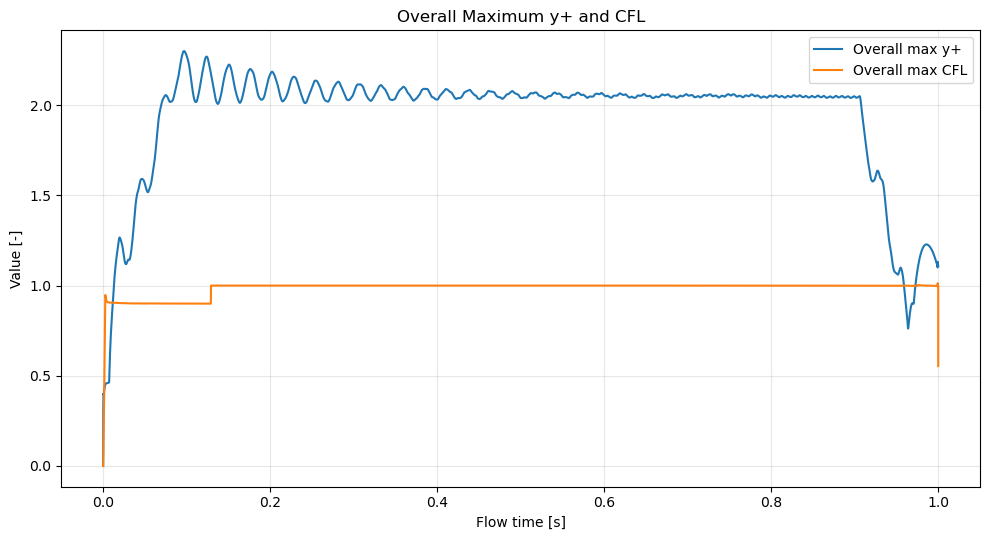

(<Figure size 1000x550 with 1 Axes>,
 <Axes: title={'center': 'Overall Maximum y+ and CFL'}, xlabel='Flow time [s]', ylabel='Value [-]'>)

In [21]:
plot_time_quantities(
    LOADED_RESULTS,
    [
        ("Overall max y+", SPECS["yplus_overall"]),
        ("Overall max CFL", SPECS["cfl_overall"]),
    ],
    title="Overall Maximum y+ and CFL",
    ylabel="Value [-]",
)


### Regional maximum \(y^+\) and CFL

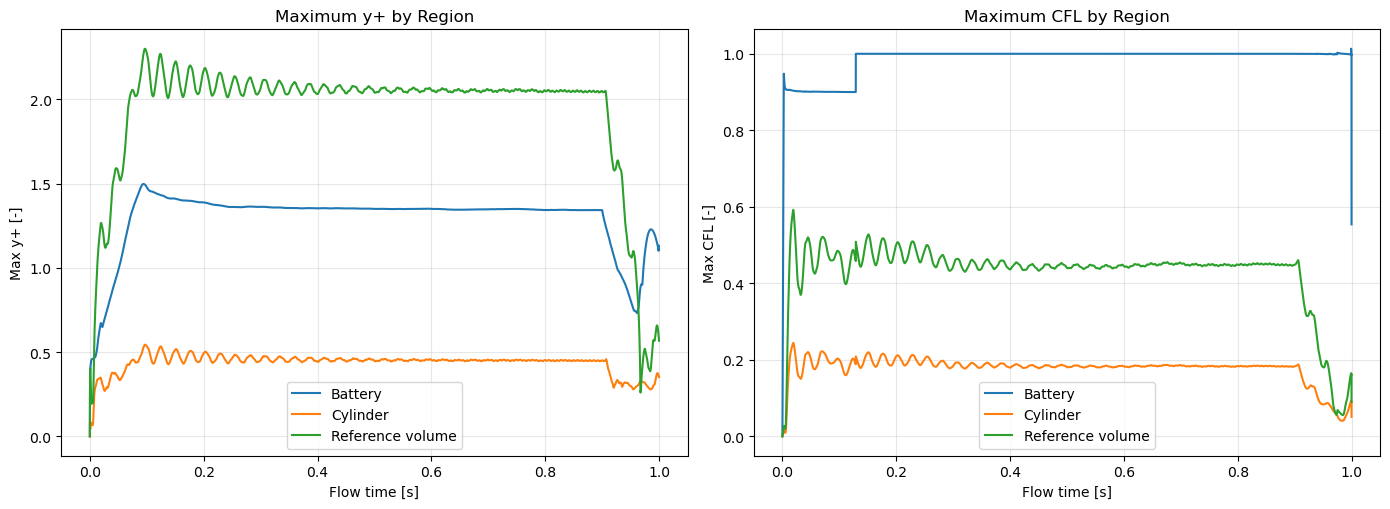

In [22]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_WIDE)

_, ax0 = plot_time_quantities(
    LOADED_RESULTS,
    [
        ("Battery", SPECS["yplus_battery"]),
        ("Cylinder", SPECS["yplus_cylinder"]),
        ("Reference volume", SPECS["yplus_reference"]),
    ],
    title="Maximum y+ by Region",
    ylabel="Max y+ [-]",
    ax=axes[0],
)

_, ax1 = plot_time_quantities(
    LOADED_RESULTS,
    [
        ("Battery", SPECS["cfl_battery"]),
        ("Cylinder", SPECS["cfl_cylinder"]),
        ("Reference volume", SPECS["cfl_reference"]),
    ],
    title="Maximum CFL by Region",
    ylabel="Max CFL [-]",
    ax=axes[1],
)

# If one side contained no data, leave a clear message.
if ax0 is None:
    axes[0].text(0.5, 0.5, "not found", ha="center", va="center")
if ax1 is None:
    axes[1].text(0.5, 0.5, "not found", ha="center", va="center")

plt.tight_layout()
plt.show()


## 4. Acoustic CFL

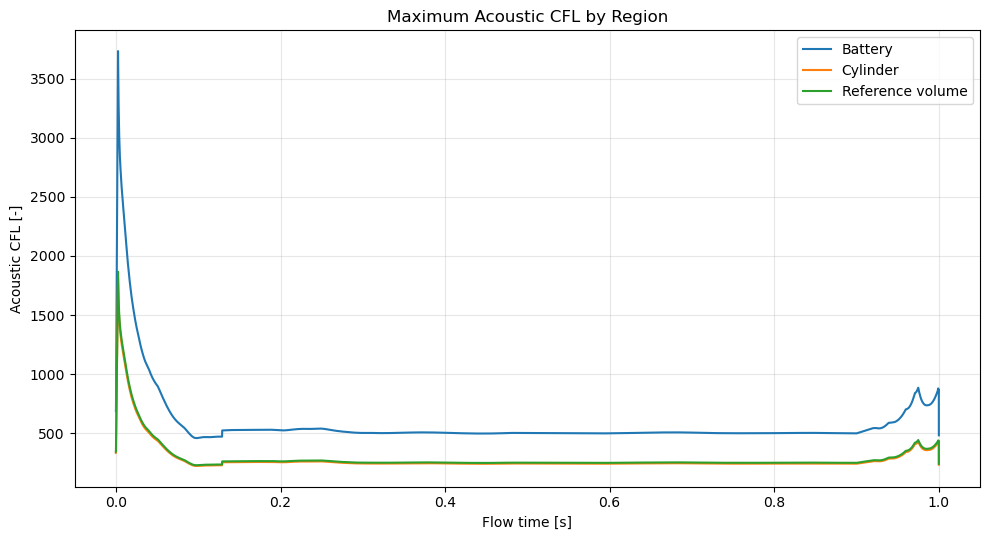

(<Figure size 1000x550 with 1 Axes>,
 <Axes: title={'center': 'Maximum Acoustic CFL by Region'}, xlabel='Flow time [s]', ylabel='Acoustic CFL [-]'>)

In [23]:
plot_time_quantities(
    LOADED_RESULTS,
    [
        ("Battery", SPECS["acoustic_battery"]),
        ("Cylinder", SPECS["acoustic_cylinder"]),
        ("Reference volume", SPECS["acoustic_reference"]),
    ],
    title="Maximum Acoustic CFL by Region",
    ylabel="Acoustic CFL [-]",
)


## 5. Iterations per time step and physical \(\Delta t\)

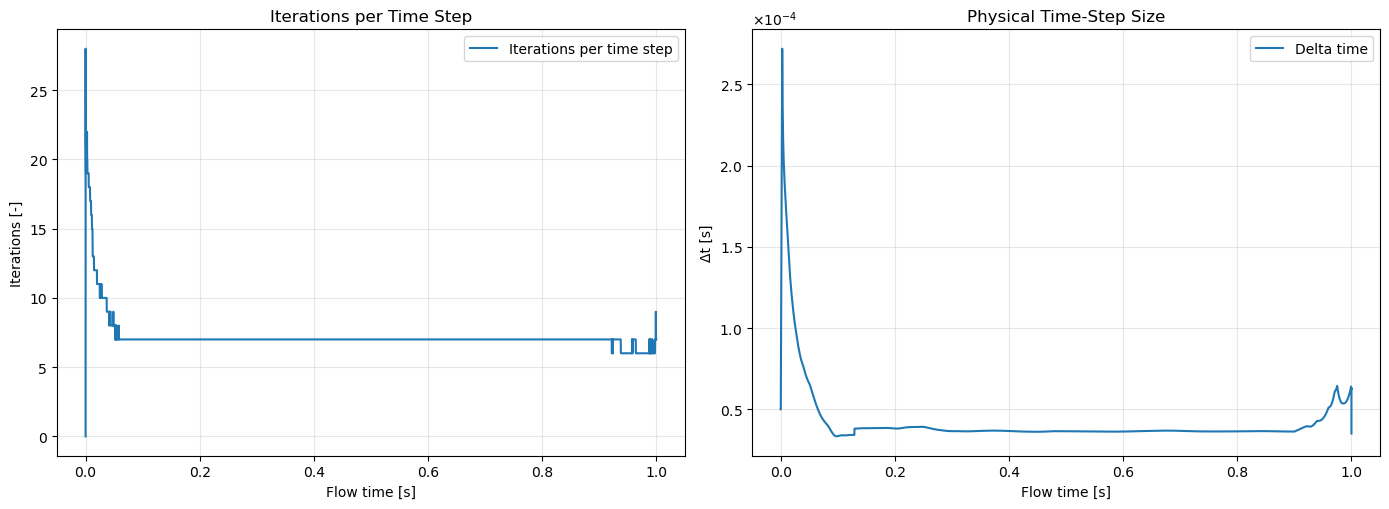

In [24]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_WIDE)

_, ax0 = plot_time_quantities(
    LOADED_RESULTS,
    [
        ("Iterations per time step", SPECS["iterations_per_timestep"]),
    ],
    title="Iterations per Time Step",
    ylabel="Iterations [-]",
    ax=axes[0],
)

_, ax1 = plot_time_quantities(
    LOADED_RESULTS,
    [
        ("Delta time", SPECS["delta_time"]),
    ],
    title="Physical Time-Step Size",
    ylabel="Δt [s]",
    ax=axes[1],
)

if ax1 is not None:
    ax1.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)

plt.tight_layout()
plt.show()


## 6. Mass-flow plots

The left axis shows **mass flow [kg/s]**. The right axis shows an **equivalent/reference volume flow [L/min]** using `AIR_DENSITY_KG_M3`.

By default the notebook keeps Fluent's signed mass flow. Set `PLOT_ABSOLUTE_MASSFLOW = True` in the configuration cell only if you deliberately want magnitudes.


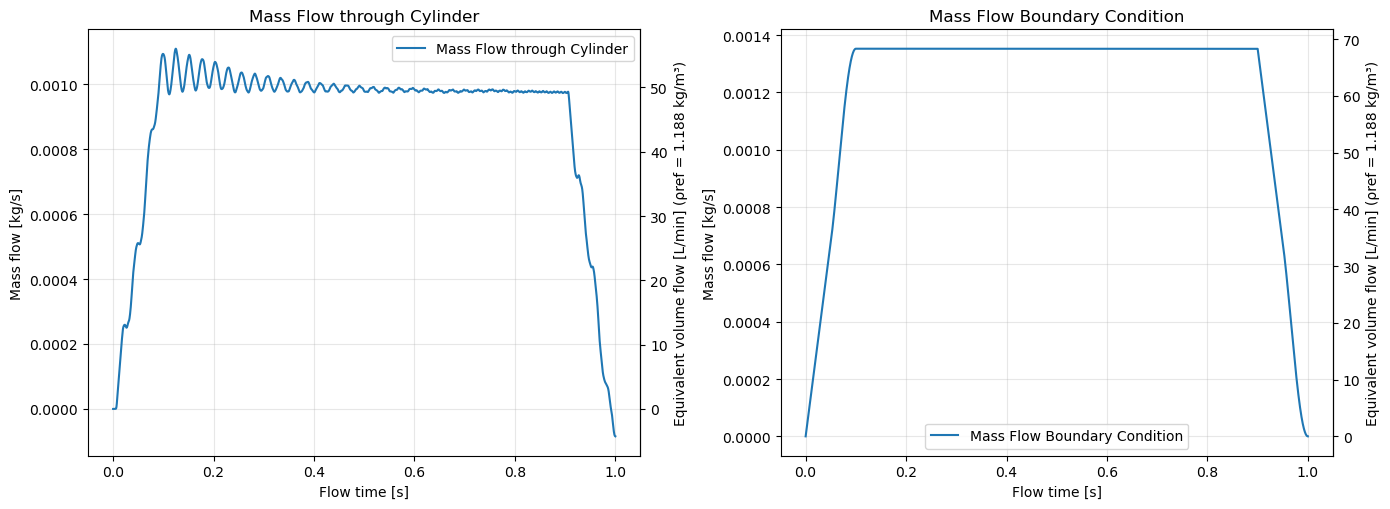

In [25]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_WIDE)

massflow_defs = [
    (
        axes[0],
        "Mass Flow through Cylinder",
        SPECS["massflow_cylinder"],
    ),
    (
        axes[1],
        "Mass Flow Boundary Condition",
        SPECS["massflow_outlet"],
    ),
]

for ax, title, aliases in massflow_defs:
    plotted = 0

    for result in active_results(LOADED_RESULTS):
        df = find_quantity(result, aliases, title)

        if df is None or df.empty:
            continue

        y = df["value"].to_numpy(dtype=float)
        if PLOT_ABSOLUTE_MASSFLOW:
            y = np.abs(y)

        ax.plot(
            df["flow_time"],
            y,
            linestyle=result["linestyle"],
            label=result["name"] if len(active_results(LOADED_RESULTS)) > 1 else title,
        )
        plotted += 1

    style_axis(ax, title, "Mass flow [kg/s]")

    if plotted:
        ax.legend()
        add_massflow_secondary_axis(ax)
    else:
        print(f"[not found] plot '{title}'")

plt.tight_layout()
plt.show()


## 7. Pressure plots

These plots are labeled **Gauge Pressure [Pa]** under the assumption that the Fluent report uses **Static Pressure**.

For Fluent Static Pressure:

\[
p_\mathrm{absolute}=p_\mathrm{gauge}+p_\mathrm{operating}.
\]

With the configured `OPERATING_PRESSURE_PA = 101325 Pa`, the reference is exactly **1 bar**. If your Fluent operating pressure is actually 101325 Pa, change that configuration value.

The pressure-difference report in your supplied example is:

\[
\Delta p = p_\mathrm{Battery}-p_\mathrm{Reference}.
\]

Gauge vs. absolute pressure does not change this difference as long as the same operating pressure applies to both regions.


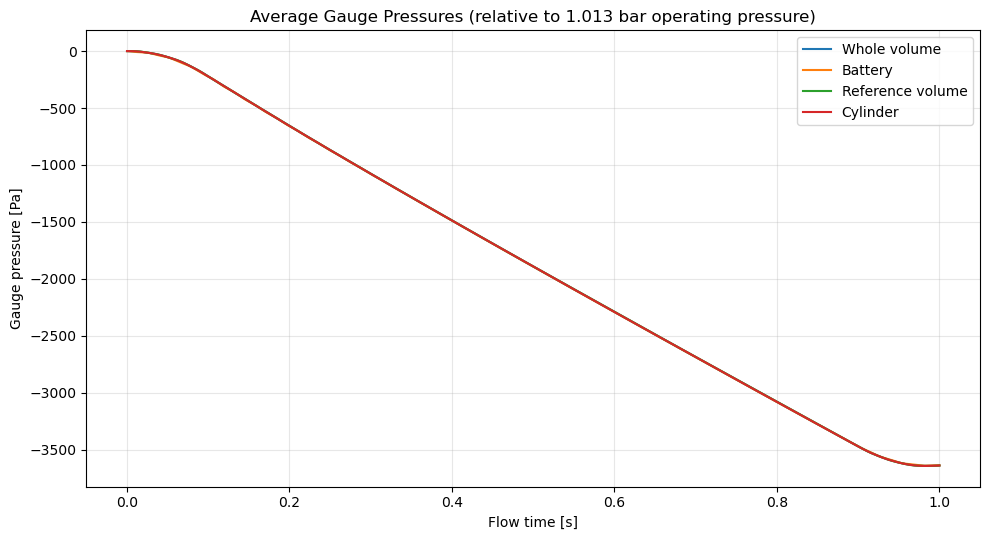

(<Figure size 1000x550 with 1 Axes>,
 <Axes: title={'center': 'Average Gauge Pressures (relative to 1.013 bar operating pressure)'}, xlabel='Flow time [s]', ylabel='Gauge pressure [Pa]'>)

In [26]:
pressure_quantities = [
    ("Whole volume", SPECS["pressure_whole"]),
    ("Battery", SPECS["pressure_battery"]),
    ("Reference volume", SPECS["pressure_reference"]),
    ("Cylinder", SPECS["pressure_cylinder"]),
]

plot_time_quantities(
    LOADED_RESULTS,
    pressure_quantities,
    title=(
        "Average Gauge Pressures "
        f"(relative to {OPERATING_PRESSURE_PA / 1e5:.3f} bar operating pressure)"
    ),
    ylabel="Gauge pressure [Pa]",
)


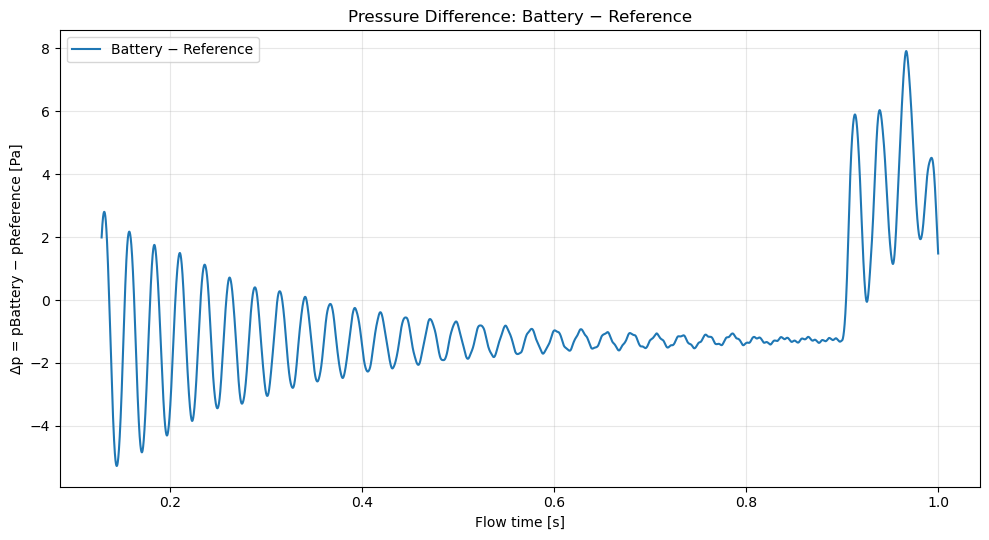

In [27]:
fig, ax = plt.subplots(figsize=FIGSIZE)
plotted = 0

for result in active_results(LOADED_RESULTS):
    df = get_pressure_difference(result)

    if df is None or df.empty:
        continue

    ax.plot(
        df["flow_time"],
        df["value"],
        linestyle=result["linestyle"],
        label=result["name"] if len(active_results(LOADED_RESULTS)) > 1 else "Battery − Reference",
    )
    plotted += 1

if plotted:
    style_axis(
        ax,
        "Pressure Difference: Battery − Reference",
        "Δp = pBattery − pReference [Pa]",
    )
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    plt.close(fig)
    print("[not found] Pressure Difference: Battery - Reference")


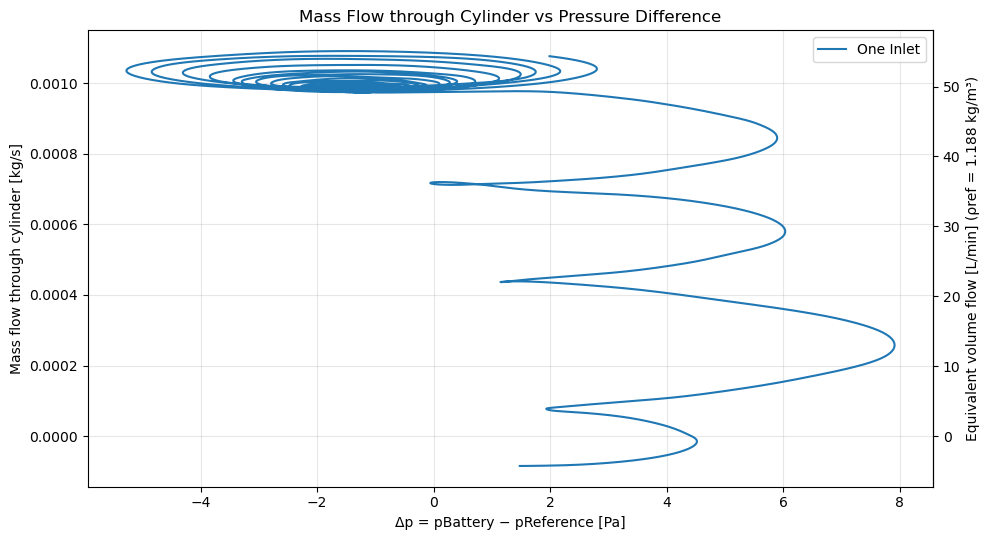

In [28]:
fig, ax = plt.subplots(figsize=FIGSIZE)
plotted = 0

for result in active_results(LOADED_RESULTS):
    dp = get_pressure_difference(result)
    mdot = find_quantity(
        result,
        SPECS["massflow_cylinder"],
        "Mass Flow through Cylinder",
    )

    corr = correlate_x_with_massflow(dp, mdot)

    if corr is None:
        print(f"[not found] {result['name']}: mass flow vs pressure difference")
        continue

    ax.plot(
        corr["x"],
        corr["massflow"],
        linestyle=result["linestyle"],
        marker=CORRELATION_MARKER,
        label=result["name"],
    )
    plotted += 1

if plotted:
    style_axis(
        ax,
        "Mass Flow through Cylinder vs Pressure Difference",
        "Mass flow through cylinder [kg/s]",
        xlabel="Δp = pBattery − pReference [Pa]",
    )
    ax.legend()
    add_massflow_secondary_axis(ax)
    plt.tight_layout()
    plt.show()
else:
    plt.close(fig)
    print("[not found] Mass Flow through Cylinder vs Pressure Difference")


## 8. Temperature plots

The average-temperature plot alone uses:

- left axis: **K**
- right axis: **°C**

The supplied `temperature-difference-rfile.out` values are consistent with:

\[
\Delta T=T_\mathrm{Battery}-T_\mathrm{Reference}.
\]

If the explicit difference report is missing, the notebook derives that same difference from the two averages.


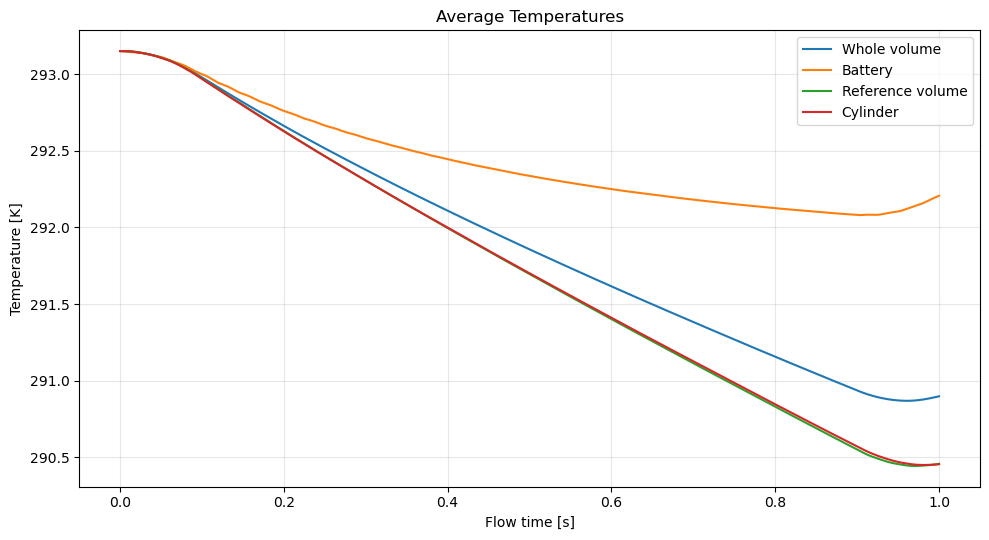

<Figure size 640x480 with 0 Axes>

In [29]:
temperature_quantities = [
    ("Whole volume", SPECS["temperature_whole"]),
    ("Battery", SPECS["temperature_battery"]),
    ("Reference volume", SPECS["temperature_reference"]),
    ("Cylinder", SPECS["temperature_cylinder"]),
]

fig, ax = plot_time_quantities(
    LOADED_RESULTS,
    temperature_quantities,
    title="Average Temperatures",
    ylabel="Temperature [K]",
)

if ax is not None:
    add_temperature_secondary_axis(ax)
    plt.tight_layout()
    plt.show()


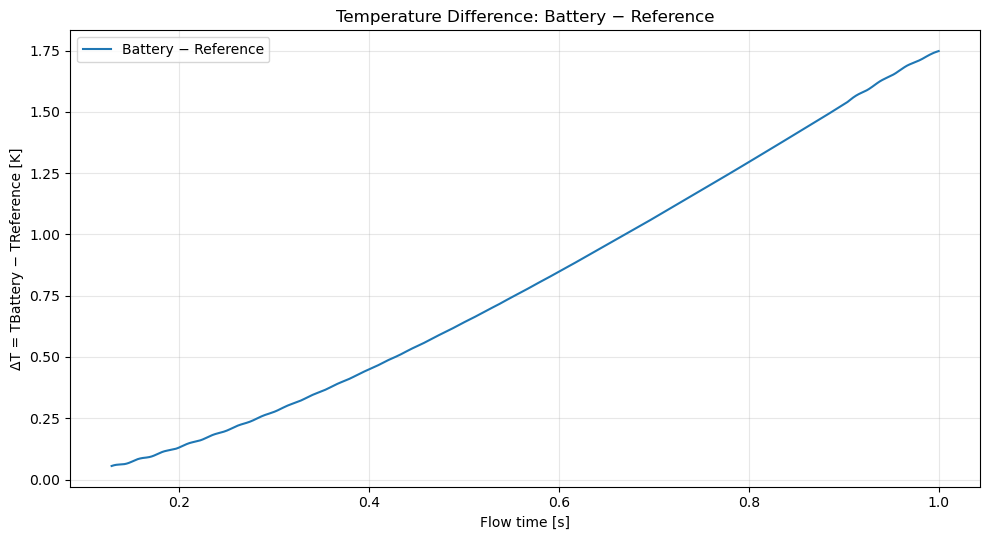

In [30]:
fig, ax = plt.subplots(figsize=FIGSIZE)
plotted = 0

for result in active_results(LOADED_RESULTS):
    df = get_temperature_difference(result)

    if df is None or df.empty:
        continue

    ax.plot(
        df["flow_time"],
        df["value"],
        linestyle=result["linestyle"],
        label=result["name"] if len(active_results(LOADED_RESULTS)) > 1 else "Battery − Reference",
    )
    plotted += 1

if plotted:
    style_axis(
        ax,
        "Temperature Difference: Battery − Reference",
        "ΔT = TBattery − TReference [K]",
    )
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    plt.close(fig)
    print("[not found] Temperature Difference: Battery - Reference")


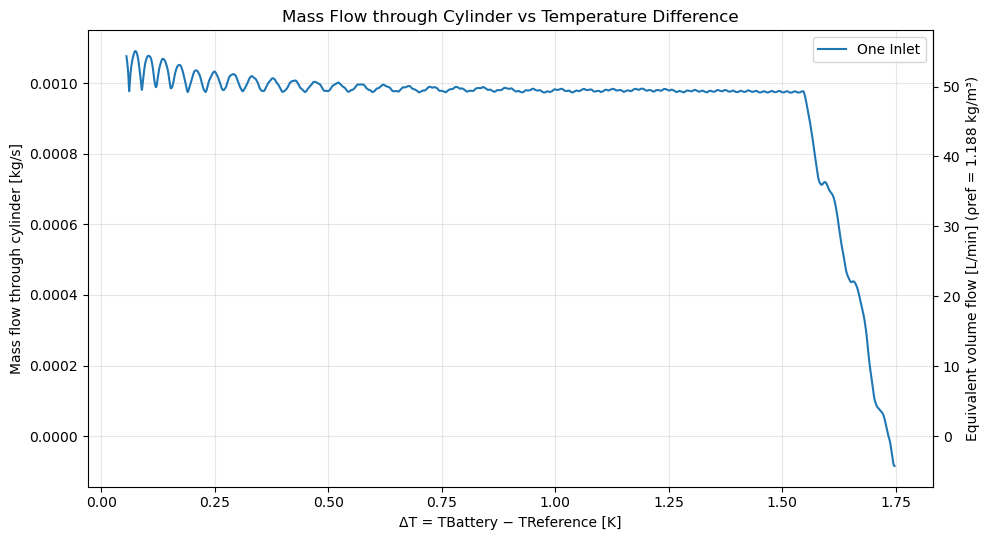

In [31]:
fig, ax = plt.subplots(figsize=FIGSIZE)
plotted = 0

for result in active_results(LOADED_RESULTS):
    dT = get_temperature_difference(result)
    mdot = find_quantity(
        result,
        SPECS["massflow_cylinder"],
        "Mass Flow through Cylinder",
    )

    corr = correlate_x_with_massflow(dT, mdot)

    if corr is None:
        print(f"[not found] {result['name']}: mass flow vs temperature difference")
        continue

    ax.plot(
        corr["x"],
        corr["massflow"],
        linestyle=result["linestyle"],
        marker=CORRELATION_MARKER,
        label=result["name"],
    )
    plotted += 1

if plotted:
    style_axis(
        ax,
        "Mass Flow through Cylinder vs Temperature Difference",
        "Mass flow through cylinder [kg/s]",
        xlabel="ΔT = TBattery − TReference [K]",
    )
    ax.legend()
    add_massflow_secondary_axis(ax)
    plt.tight_layout()
    plt.show()
else:
    plt.close(fig)
    print("[not found] Mass Flow through Cylinder vs Temperature Difference")


# 9. Heat Transfer Plots

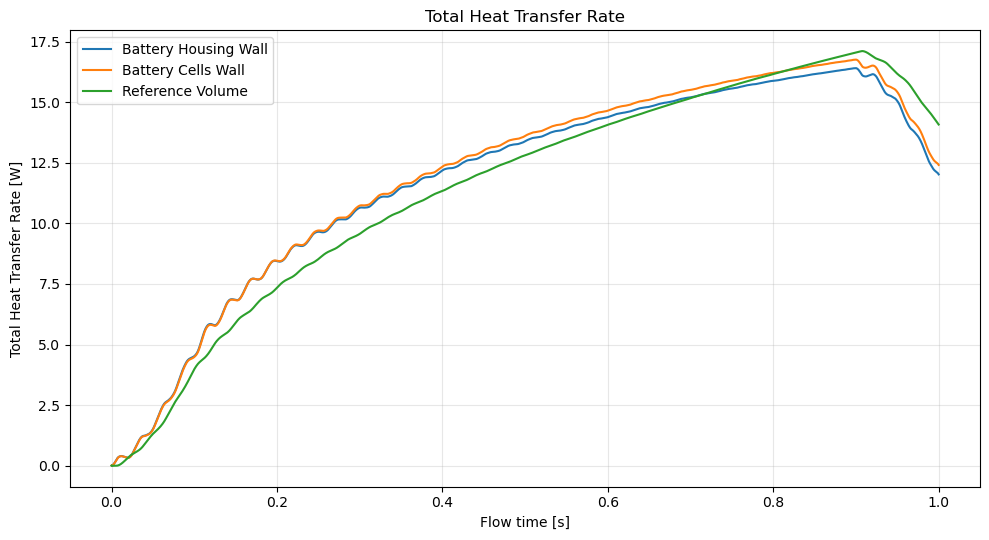

In [32]:
# ============================================================
# HEAT TRANSFER RATES
# Total Heat Transfer Rate [W]
# ============================================================

heat_transfer_specs = [
    (
        "Battery Housing Wall",
        [
            "heat-transfer-wall",
            "heat_transfer_wall",
            "heattransferwall",
            "heat-transfer-housing",
            "heat-transfer-battery-wall",
            "heat-transfer-battery-housing",
            "total-heat-transfer-rate-wall",
        ],
    ),
    (
        "Battery Cells Wall",
        [
            "heat-transfer-modules",
            "heat_transfer_modules",
            "heattransfermodules",
            "heat-transfer-cells",
            "heat_transfer_cells",
            "heattransfercells",
            "heat-transfer-battery-cells",
            "total-heat-transfer-rate-modules",
        ],
    ),
    (
        "Reference Volume",
        [
            "heat-transfer-refvolume",
            "heat_transfer_refvolume",
            "heattransferrefvolume",
            "heat-transfer-refvol",
            "heat-transfer-reference",
            "heat-transfer-reference-volume",
            "total-heat-transfer-rate-refvolume",
        ],
    ),
]

fig, ax = plt.subplots(figsize=FIGSIZE)

colors = _default_colors(len(heat_transfer_specs))
plotted = 0

for quantity_index, (quantity_label, aliases) in enumerate(heat_transfer_specs):

    for result in active_results(LOADED_RESULTS):

        df = find_quantity(
            result,
            aliases,
            f"Heat Transfer: {quantity_label}",
        )

        if df is None or df.empty:
            continue

        ax.plot(
            df["flow_time"],
            df["value"],
            color=colors[quantity_index],
            linestyle=result["linestyle"],
            label=result_label(
                quantity_label,
                result,
                LOADED_RESULTS,
            ),
        )

        plotted += 1

if plotted:

    style_axis(
        ax,
        title="Total Heat Transfer Rate",
        ylabel="Total Heat Transfer Rate [W]",
    )

    ax.legend()
    plt.tight_layout()
    plt.show()

else:

    plt.close(fig)
    print("[not found] Heat transfer data")

## 9. Plot every remaining quantity

Any plottable Fluent report variable that has **not** already been used above is plotted here.

The notebook deliberately labels the vertical axis as **native Fluent report units** because a previously unknown report name does not provide enough information to infer a trustworthy physical unit automatically. For example, your `heat_transfer.out` variables should appear here unless you add a dedicated heat-transfer section later.


Additional quantity groups to plot: 1


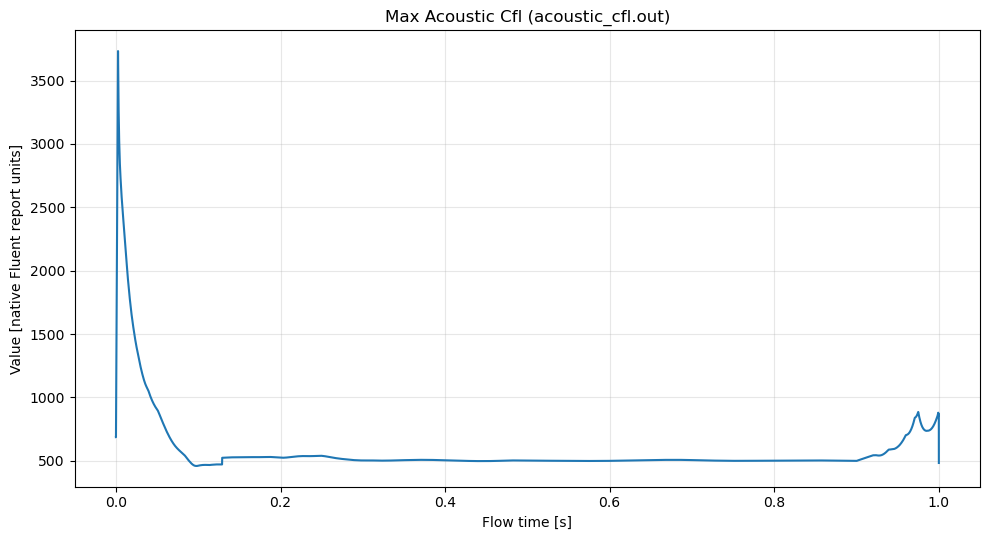

In [33]:
def combine_exact_pair(result, file_norm, var_norm):
    data = result["data"]

    subset = data[
        (data["source_file_norm"] == file_norm) &
        (data["var_norm"] == var_norm)
    ].copy()

    if subset.empty:
        return None

    subset["_time_key"] = subset["flow_time"].round(FLOW_TIME_ROUND_DECIMALS)

    subset = subset.sort_values(
        ["_time_key", "_source_index"],
        kind="stable",
    )

    subset = subset.drop_duplicates("_time_key", keep="last")
    subset = subset.sort_values("flow_time", kind="stable").reset_index(drop=True)

    return subset


all_remaining_keys = set()

for result in active_results(LOADED_RESULTS):
    data = result["data"]
    pairs = data[
        ["source_file_norm", "var_norm", "source_file", "variable_name"]
    ].drop_duplicates()

    for _, row in pairs.iterrows():
        key = (row["source_file_norm"], row["var_norm"])
        if key not in result["used_pairs"]:
            all_remaining_keys.add(key)


if not all_remaining_keys:
    print("No additional unplotted quantities remain.")
else:
    print(f"Additional quantity groups to plot: {len(all_remaining_keys)}")

    for file_norm, var_norm in sorted(all_remaining_keys):
        fig, ax = plt.subplots(figsize=FIGSIZE)
        plotted = 0
        display_name = None

        for result in active_results(LOADED_RESULTS):
            df = combine_exact_pair(result, file_norm, var_norm)

            if df is None or df.empty:
                continue

            if display_name is None:
                raw = df["variable_name"].iloc[0]
                source_file = df["source_file"].iloc[0]
                display_name = f"{pretty_name(raw)} ({source_file})"

            ax.plot(
                df["flow_time"],
                df["value"],
                linestyle=result["linestyle"],
                label=result["name"],
            )
            plotted += 1

        if not plotted:
            plt.close(fig)
            continue

        style_axis(
            ax,
            display_name,
            "Value [native Fluent report units]",
        )

        if len(active_results(LOADED_RESULTS)) > 1:
            ax.legend()

        plt.tight_layout()
        plt.show()


## 10. Notes for extending the notebook

- **Different report/file spelling:** first check the *Detected variables* inventory. If a variable was not recognized, add one of its normalized names to the appropriate `SPECS[...]` alias list.
- **Continuation folders:** later paths in one result configuration overwrite earlier paths only where flow times overlap.
- **Comparison runs:** line style identifies the result configuration; the physical quantity/region keeps the same default Matplotlib color within each plot.
- **Mass flow:** the right L/min scale is a reference-density conversion. The kg/s curve is the original Fluent report value.
- **Pressure:** the notebook does not add operating pressure. It plots the Fluent gauge/static report values directly.
- **Unknown quantities:** no unit is guessed automatically in the final section.
